## Steps

- predict on all examples for rubber in Cambodia (possibly other classes and other countries later)
- get the sum of rubber probabilities on all these examples

- replace all rubber with 0s in tab data
- predict again, and get the sum of rubber probabilities
- is it lower? 
- if yes, try to make a plot that links the tab value with the class prob

In [1]:
import sys
import os
sys.path.append('../')


import matplotlib.pyplot as plt
from IPython.display import clear_output
import json
import itertools 
import random
import matplotlib.pyplot as plt
import pprint
sys.path.append('../')
import tqdm
import pickle
import pprint

from sklearn.metrics import classification_report
import torch.nn as nn
import rasterio
import numpy as np
import torch
import torch.nn.functional as F
import utils
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, Polygon
from shapely.geometry import box
from shapely.ops import nearest_points

import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING
from model.model import MultiModalDriverClassifier
from utils import get_tiles_as_gdf

import wandb

inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

np.set_printoptions(suppress=True)

np.set_printoptions(suppress=True)

In [2]:
wandb_id = 'fuvmj0ci'


In [3]:
device = 'cuda'

model_dir = os.path.join('../models_trained', wandb_id)
config_path = os.path.join(model_dir, 'config.json')
with open(config_path) as source:
    config = json.loads(source.read())


#Load trained model
model = MultiModalDriverClassifier(11,  **config)
model = model.to(device)

trained_weights = f'../models_trained/{wandb_id}/last.pt'
_ = model.load_state_dict(torch.load(trained_weights)['state_dict'])
_ = model.eval()



In [4]:
df = pd.read_csv('/home/jan/Documents/EPFL/project_2/data/labels/dataset_v5/labels_no_regrowth.csv')
cambodia = df.loc[df.country == 'Cambodia']
cambodia.to_csv('../data/tmp/cambodia_tmp.csv',   index=False)
config['data']['annotation_file'] = '../data/tmp/cambodia_tmp.csv'
# fetch dataloaders
dataloaders = dataloader.fetch_dataloader(
    ['val'], config)
val_dl = dataloaders['val']

In [24]:
class_name = "rubber"
# Separate 'rubber' and other classes
cls_idx = LABEL_MAPPING.get('rubber')
tab_values = [coef/10 for coef in range(50)]


In [29]:
def get_results(cls_idx, tabular_values, model=model, val_dl=val_dl):

    model.eval()

    preds_batches = []
    targets_batches = []

    all_mean_probs = []

    for coeff in tabular_values:
        print(coeff)
        for data_batch, labels_batch in val_dl:

            image_batch, loc_batch, expansion_rates_batch, forestloss_batch, labels_batch = data_batch[0].to(device), data_batch[1].to(device), data_batch[2].to(device), data_batch[3].to(device), labels_batch.to(device)

            expansion_rates_batch[:,cls_idx] = expansion_rates_batch[:,cls_idx]*coeff



            y_hat = model(image_batch, loc_batch, expansion_rates_batch, forestloss_batch)


            y_hat = F.softmax(y_hat, dim=1)
            y_hat = y_hat.cpu().detach()
            labels_batch = labels_batch.cpu().detach()

            preds_batches.append(y_hat)
            targets_batches.append(labels_batch)

        probabilities = torch.cat(preds_batches, axis=0).cpu().detach()
        mean_probs = probabilities.mean(axis=0).numpy()
        all_mean_probs.append(mean_probs)

        preds = probabilities.argmax(dim=1).numpy()

    return preds, np.stack(all_mean_probs)


,driver,sampleid,dataset,country,geometry,block_id,split,dst_size
0,urban,100015773,worldcover.csv,Ghana,POINT (-1.76827 4.95503),147.0,val,NaN
1,urban,100015774,worldcover.csv,Ghana,POINT (-1.75938 4.95503),147.0,val,NaN
2,urban,100015775,worldcover.csv,Ghana,POINT (-1.96393 4.88389),147.0,val,NaN
3,urban,100015776,worldcover.csv,Ghana,POINT (-1.83053 4.88389),147.0,val,NaN
4,urban,100016245,worldcover.csv,Ghana,POINT (-1.53705 6.56768),147.0,val,NaN
...,...,...,...,...,...,...,...,...
1188,palm oil,90167957,palm_oil.csv,Ghana,POINT (-2.39271 4.99872),147.0,val,NaN
1189,palm oil,90099725,palm_oil.csv,Ghana,POINT (-0.96079 6.24388),147.0,val,NaN
1190,palm oil,90099836,palm_oil.csv,Ghana,POINT (-1.19202 5.87925),147.0,val,NaN
1191,palm oil,90167904,palm_oil.csv,Ghana,POINT (-1.93025 5.14991),147.0,val,NaN


In [20]:
tab_values = [coef/10 for coef in range(50)]


In [12]:
_preds, all_mean_probs = get_results(cls_idx, tabular_values=tab_values)

0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0
3.1
3.2
3.3
3.4
3.5
3.6
3.7
3.8
3.9
4.0
4.1
4.2
4.3
4.4
4.5
4.6
4.7
4.8
4.9


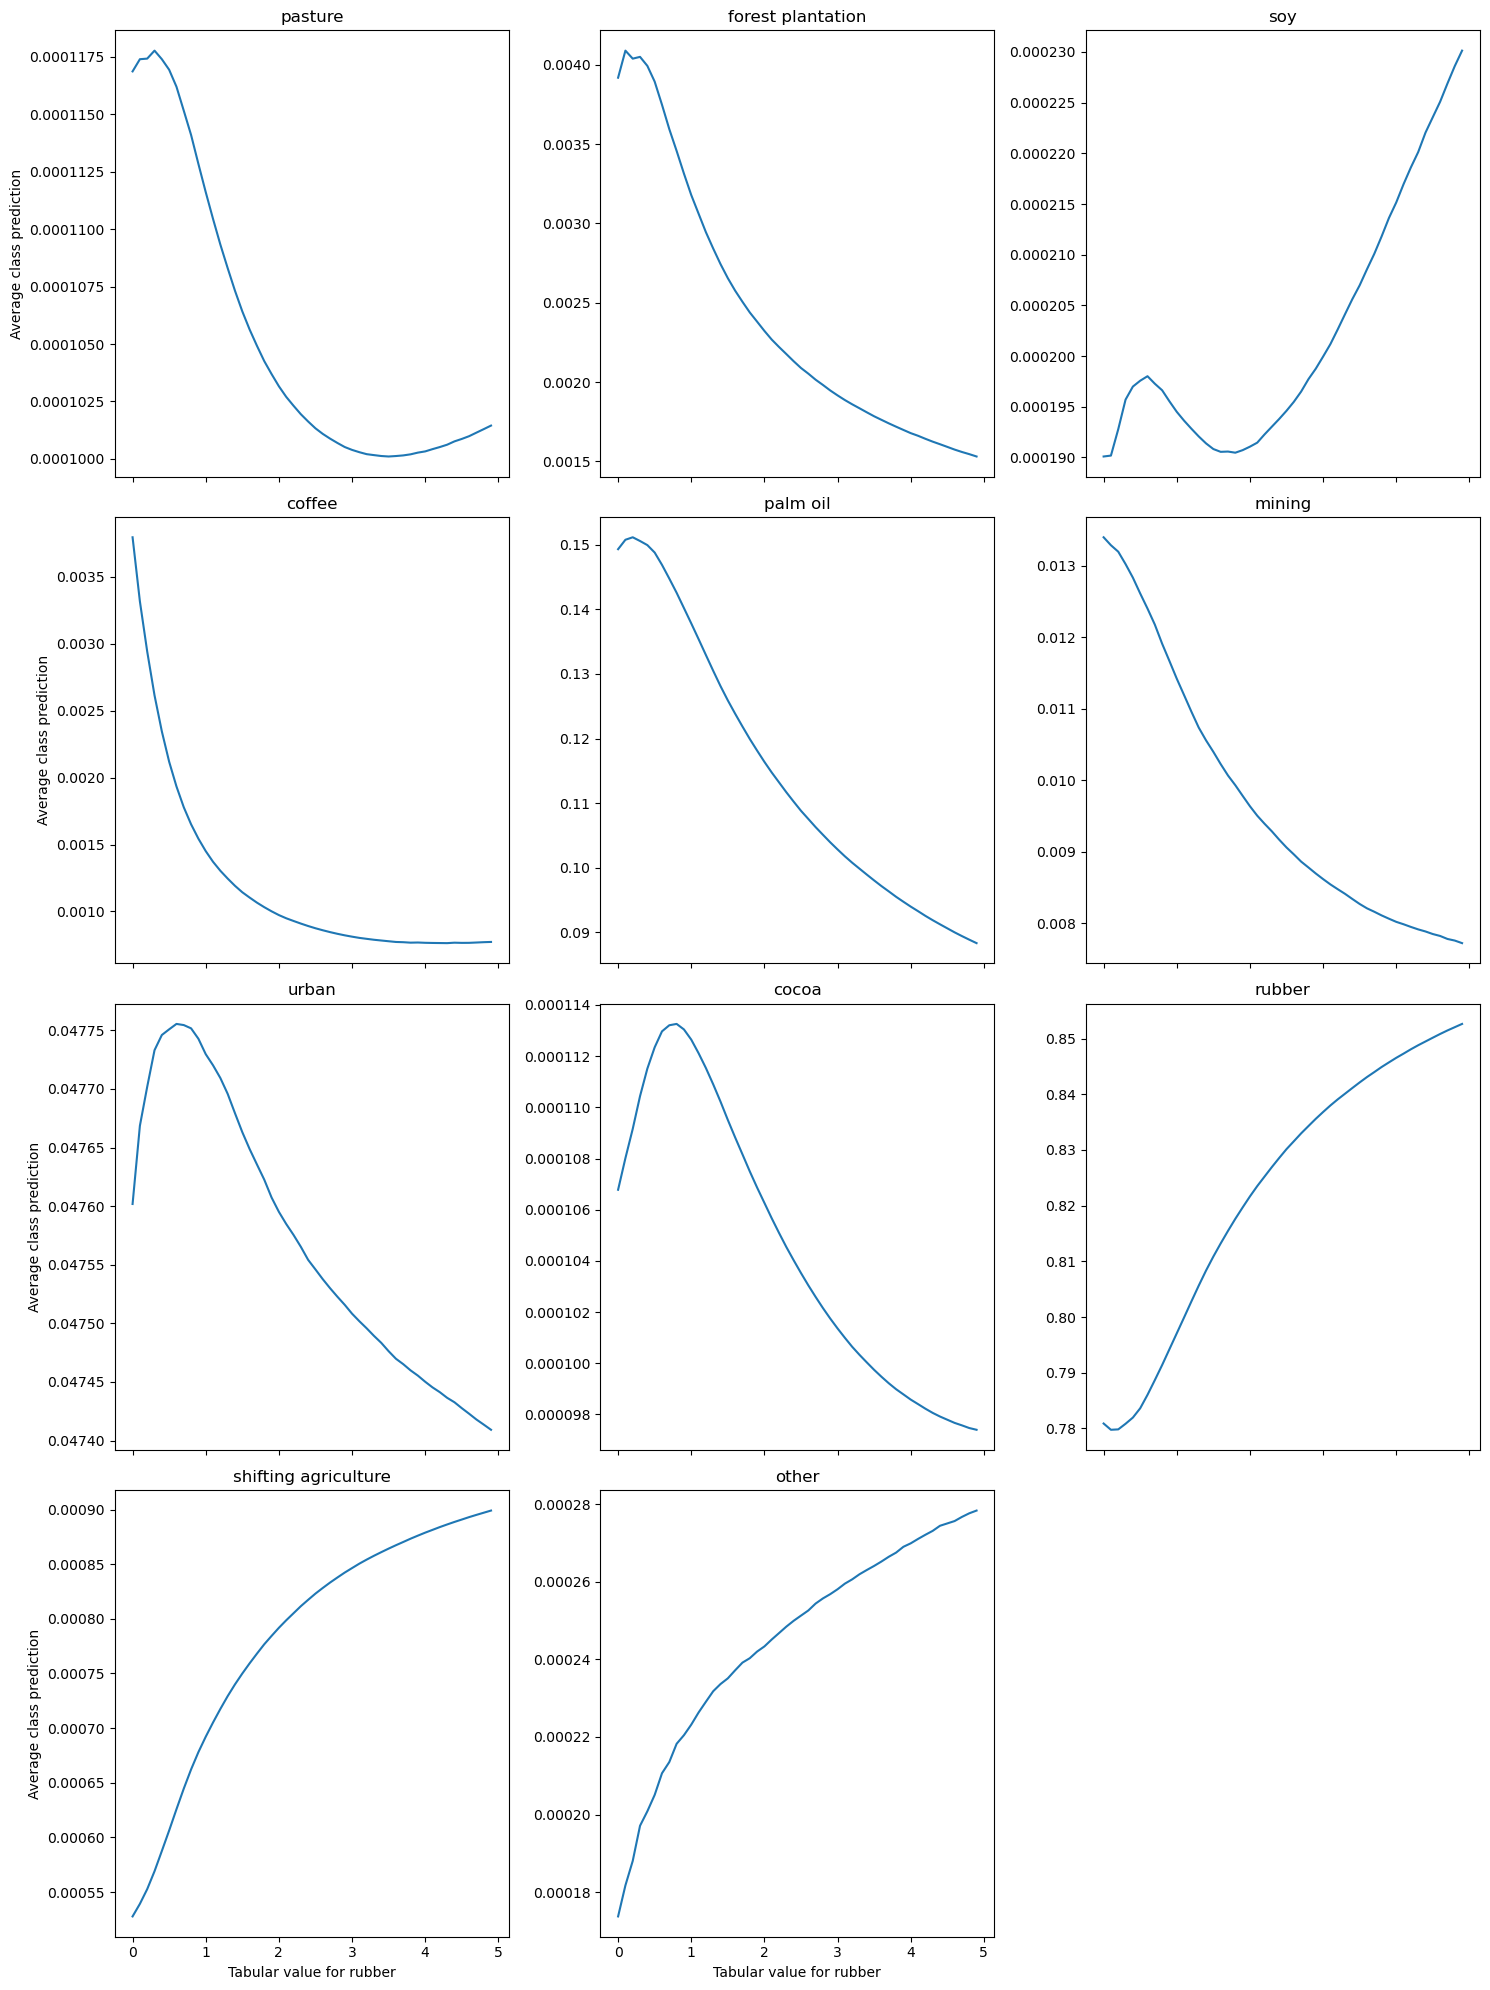

In [21]:

plot_all_classes(all_mean_probs, tab_values, 'rubber')

In [18]:
def plot_all_classes(probabilities, x_axis, class_name):

    # Adjust grid size as needed; here we're using a 4x3 grid to accommodate up to 12 subplots
    fig, axs = plt.subplots(4, 3, figsize=(15, 20), sharex=True)

    limits = {}

    #x_axis_vals = 

    # Loop through LABEL_MAPPING and plot each on its own subplot
    for idx, (name, cls_idx) in enumerate(LABEL_MAPPING.items()):
        row = idx // 3
        col = idx % 3
        axs[row, col].plot(x_axis, probabilities[:, cls_idx])
        axs[row, col].set_title(name)

        if idx in [0,3,6,9]:
            axs[row, col].set_ylabel('Average class prediction')
        if idx in [9,10,11]:
            axs[row, col].set_xlabel(f'Tabular value for {class_name}')

    # Hide any unused subplots if the grid has extra spaces
    for i in range(len(LABEL_MAPPING), 12):
        fig.delaxes(axs.flat[i])

    #plt.xlabel("Coefficients")
    plt.tight_layout()
    plt.show()


In [22]:
def plot_averaged_classes(probabilities, x_axis, class_name):


    # Adjust grid size for two subplots
    fig, axs = plt.subplots(1, 2, figsize=(15, 7), sharex=True)

    # Separate 'rubber' and other classes
    target_cls_idx = LABEL_MAPPING.get(class_name)
    other_classes_idx = [cls_idx for name, cls_idx in LABEL_MAPPING.items() if name != class_name]

    # Plot for 'rubber'
    axs[0].plot(coeffs, probabilities[:, target_cls_idx])
    axs[0].set_title(class_name)
    axs[0].set_ylabel('Average class prediction')
    axs[0].set_xlabel(f'Tabular value for {class_name}')

    # Plot for average of other classes
    average_probs = np.mean(probabilities[:, other_classes_idx], axis=1)
    axs[1].plot(coeffs, average_probs)
    axs[1].set_title('Average of Other Classes')
    axs[1].set_xlabel(f'Tabular value for {class_name}')

    # Tight layout
    plt.tight_layout()
    plt.show()


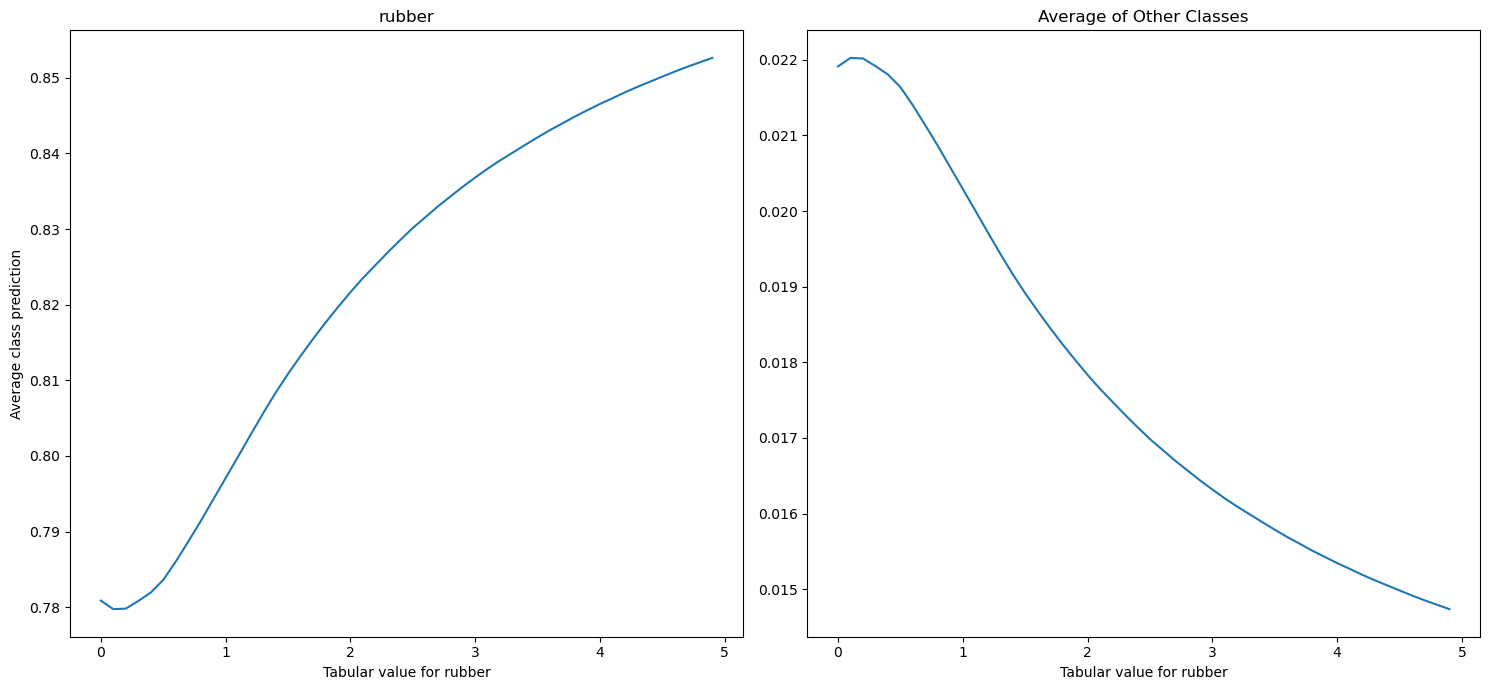

In [23]:
plot_averaged_classes(all_mean_probs, tab_values, 'rubber')

### Palm oil - Cambodia

In [30]:
class_name = "palm oil"
cls_idx = LABEL_MAPPING.get(class_name)
tab_values = [coef/10 for coef in range(50)]
_preds, all_mean_probs = get_results(cls_idx, tabular_values=tab_values)


0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0
3.1
3.2
3.3
3.4
3.5
3.6
3.7
3.8
3.9
4.0
4.1
4.2
4.3
4.4
4.5
4.6
4.7
4.8
4.9


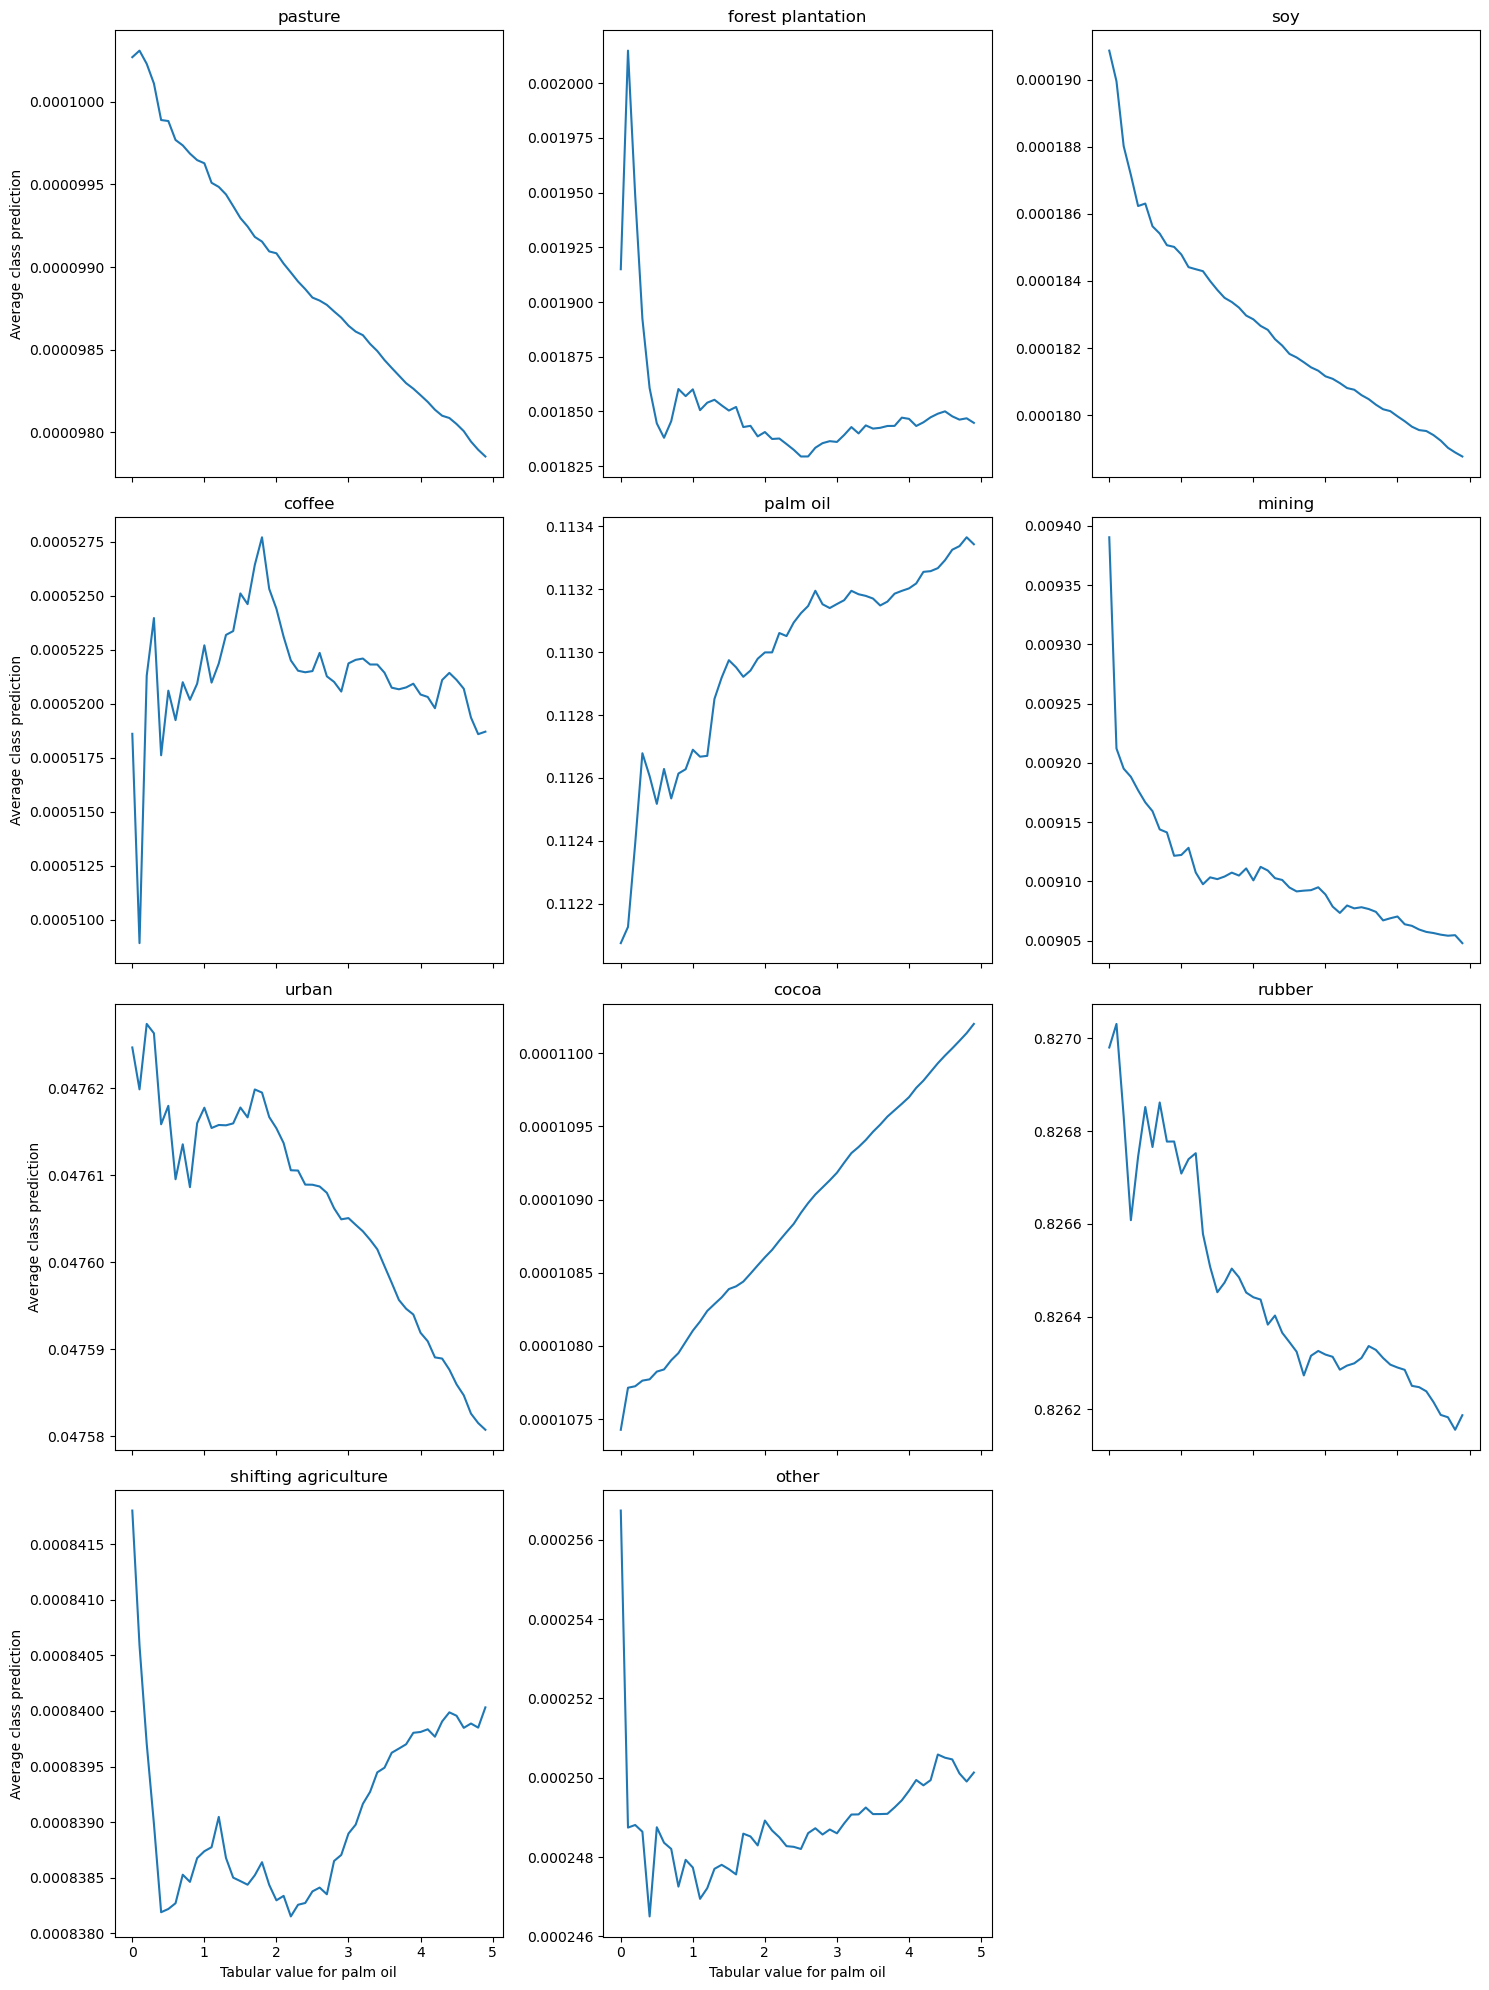

In [31]:
plot_all_classes(all_mean_probs, tab_values, class_name)


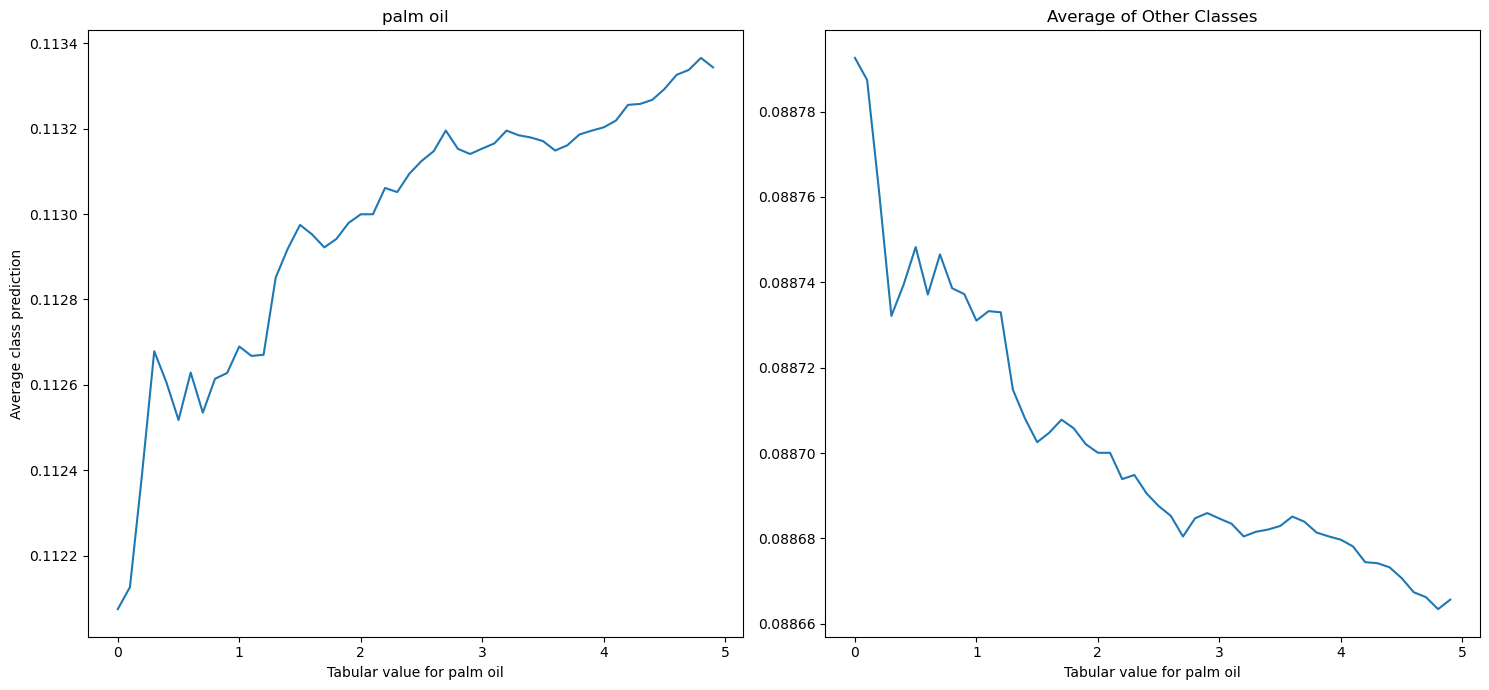

In [32]:

plot_averaged_classes(all_mean_probs, tab_values, class_name)

### Urban

In [33]:
class_name = "urban"
cls_idx = LABEL_MAPPING.get(class_name)
tab_values = [coef/10 for coef in range(50)]
_preds, all_mean_probs = get_results(cls_idx, tabular_values=tab_values)


0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0
3.1
3.2
3.3
3.4
3.5
3.6
3.7
3.8
3.9
4.0
4.1
4.2
4.3
4.4
4.5
4.6
4.7
4.8
4.9


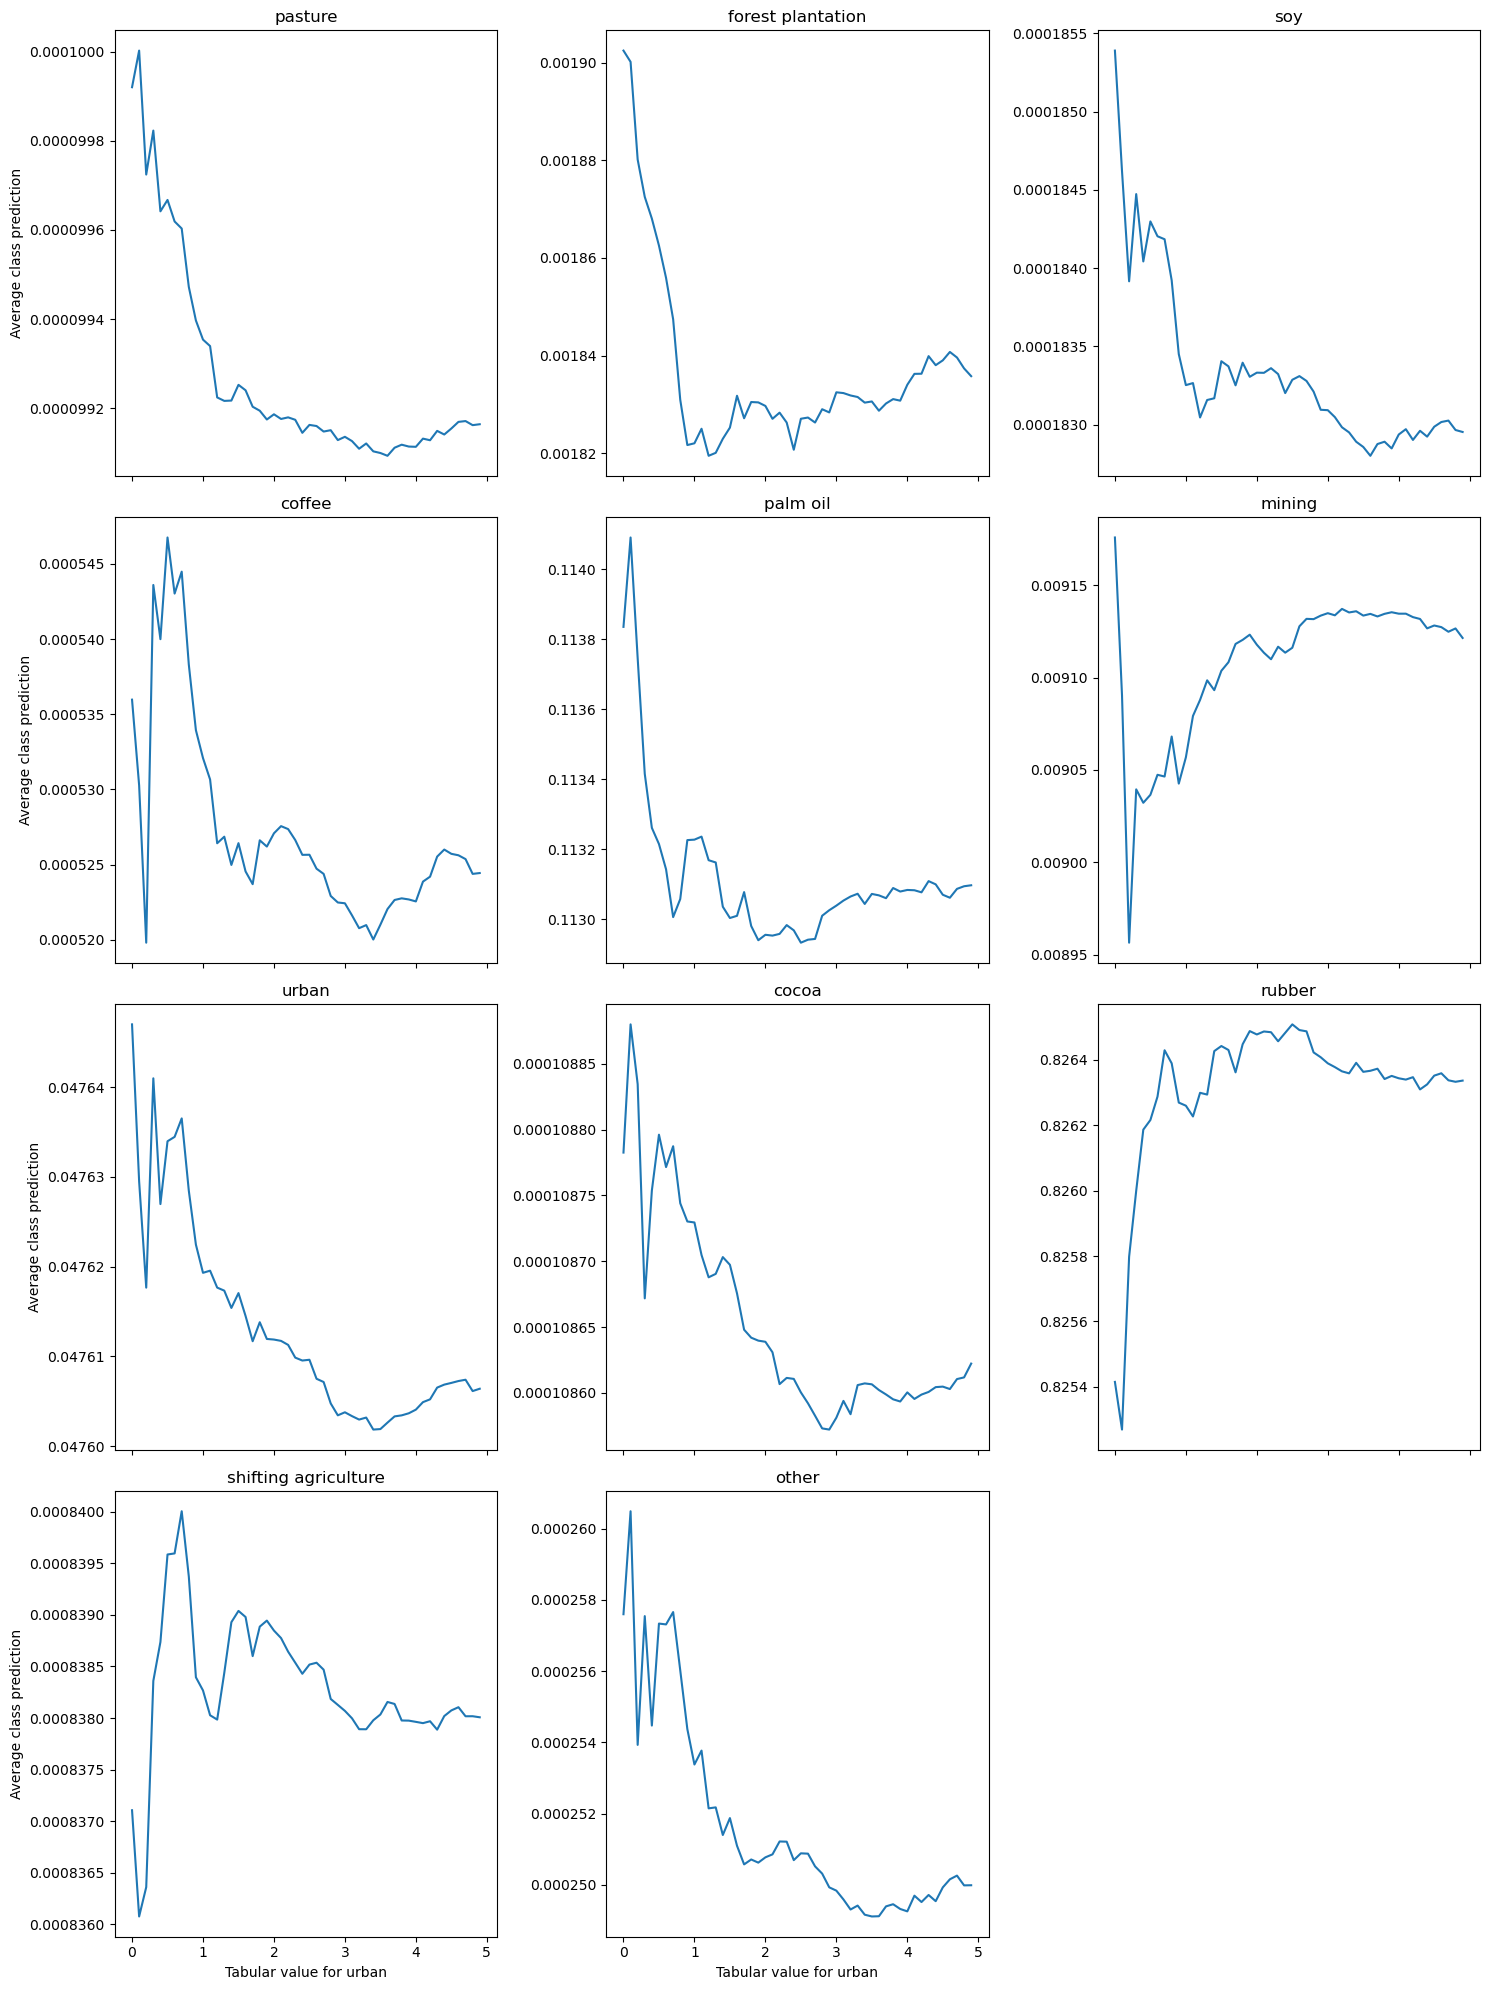

In [34]:
plot_all_classes(all_mean_probs, tab_values, class_name)



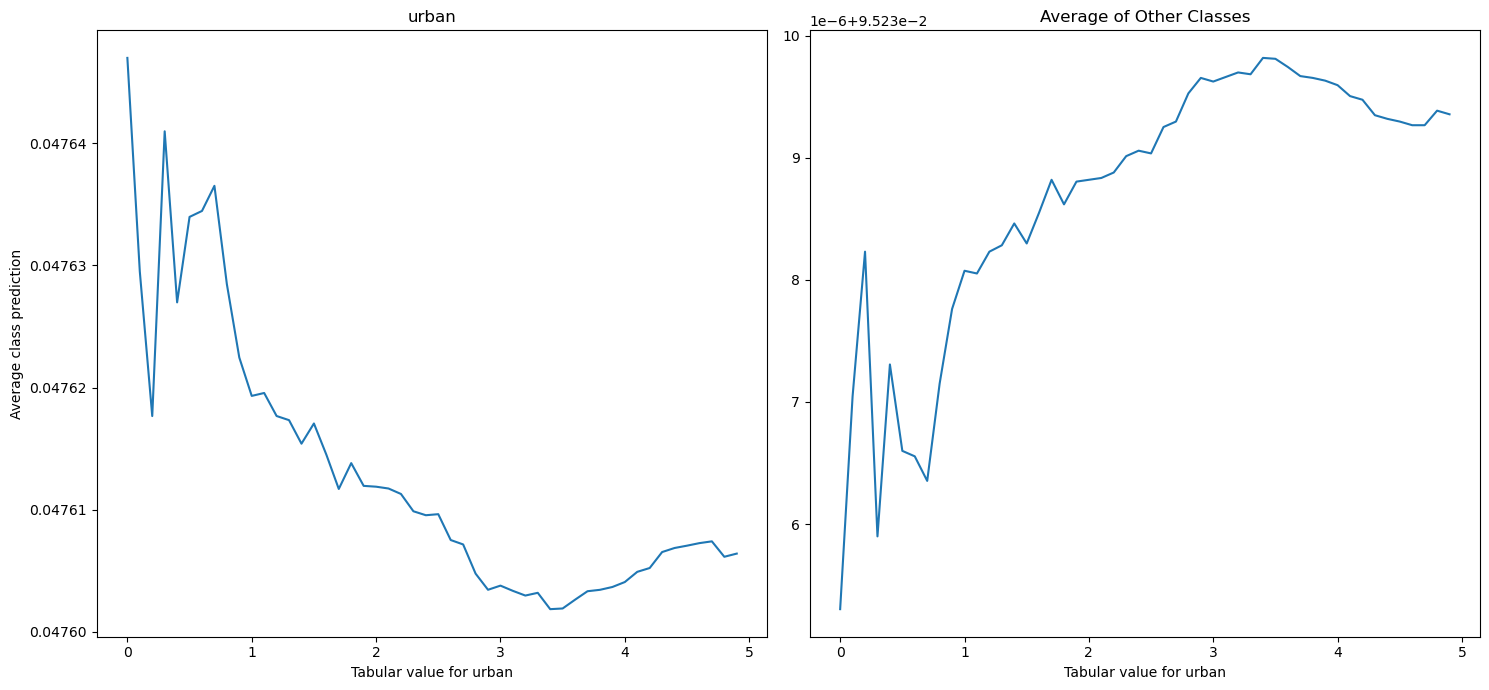

In [35]:
plot_averaged_classes(all_mean_probs, tab_values, class_name)

# Ghana

In [52]:
ghana

,driver,sampleid,dataset,country,geometry,block_id,split,dst_size
2076,urban,100015773,worldcover.csv,Ghana,POINT (-1.7682749981795174 4.955034730598358),147.0,4,NaN
2077,urban,100015774,worldcover.csv,Ghana,POINT (-1.7593816768667343 4.955034730598358),147.0,4,NaN
2078,urban,100015775,worldcover.csv,Ghana,POINT (-1.9639280670607486 4.88388816031149),147.0,4,NaN
2079,urban,100015776,worldcover.csv,Ghana,POINT (-1.8305282473690014 4.88388816031149),147.0,4,NaN
2273,urban,100016245,worldcover.csv,Ghana,POINT (-1.5370486440471518 6.56767660094949),147.0,4,NaN
...,...,...,...,...,...,...,...,...
19259,palm oil,90167957,palm_oil.csv,Ghana,POINT (-2.3927076750165512 4.99872029896546),147.0,4,NaN
19263,palm oil,90099725,palm_oil.csv,Ghana,POINT (-0.9607931121300338 6.243875110531239),147.0,4,NaN
19264,palm oil,90099836,palm_oil.csv,Ghana,POINT (-1.1920194662623975 5.879248937802525),147.0,4,NaN
20986,palm oil,90167904,palm_oil.csv,Ghana,POINT (-1.9302549667518212 5.149906760825495),147.0,4,NaN


In [39]:
ghana = df.loc[df.country == 'Ghana']
ghana.to_csv('../data/tmp/ghana_tmp.csv',   index=False)
config['data']['annotation_file'] = '../data/tmp/ghana_tmp.csv'
# fetch dataloaders
dataloaders = dataloader.fetch_dataloader(
    ['val'], config)
val_dl = dataloaders['val']

In [48]:
def predict(model, dataloader):
    
    model.eval()

    preds_batches = []
    targets_batches = []

    for data_batch, labels_batch in dataloader:

        image_batch, loc_batch, expansion_rates_batch, forestloss_batch, labels_batch = data_batch[0].to(device), data_batch[1].to(device), data_batch[2].to(device), data_batch[3].to(device), labels_batch.to(device)
        y_hat = model(image_batch, loc_batch, expansion_rates_batch, forestloss_batch)


        y_hat = F.softmax(y_hat, dim=1)
        y_hat = y_hat.cpu().detach()
        labels_batch = labels_batch.cpu().detach()

        preds_batches.append(y_hat)
        targets_batches.append(labels_batch)
        
    probabilities = torch.cat(preds_batches, axis=0).cpu().detach()

    preds = probabilities.argmax(dim=1).numpy()
    
    return probabilities.numpy(), preds

In [49]:
probs, preds = predict(model, val_dl)

In [54]:
np.unique(preds, return_counts=True)

(array([4, 5, 6, 7, 9]), array([   9,   55,   45, 1057,   27]))

### Palm oil

In [58]:
class_name = "palm oil"
cls_idx = LABEL_MAPPING.get(class_name)
tab_values = [coef/10 for coef in range(50)]
_preds, all_mean_probs = get_results(cls_idx, tabular_values=tab_values, val_dl=val_dl)


0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0
3.1
3.2
3.3
3.4
3.5
3.6
3.7
3.8
3.9
4.0
4.1
4.2
4.3
4.4
4.5
4.6
4.7
4.8
4.9


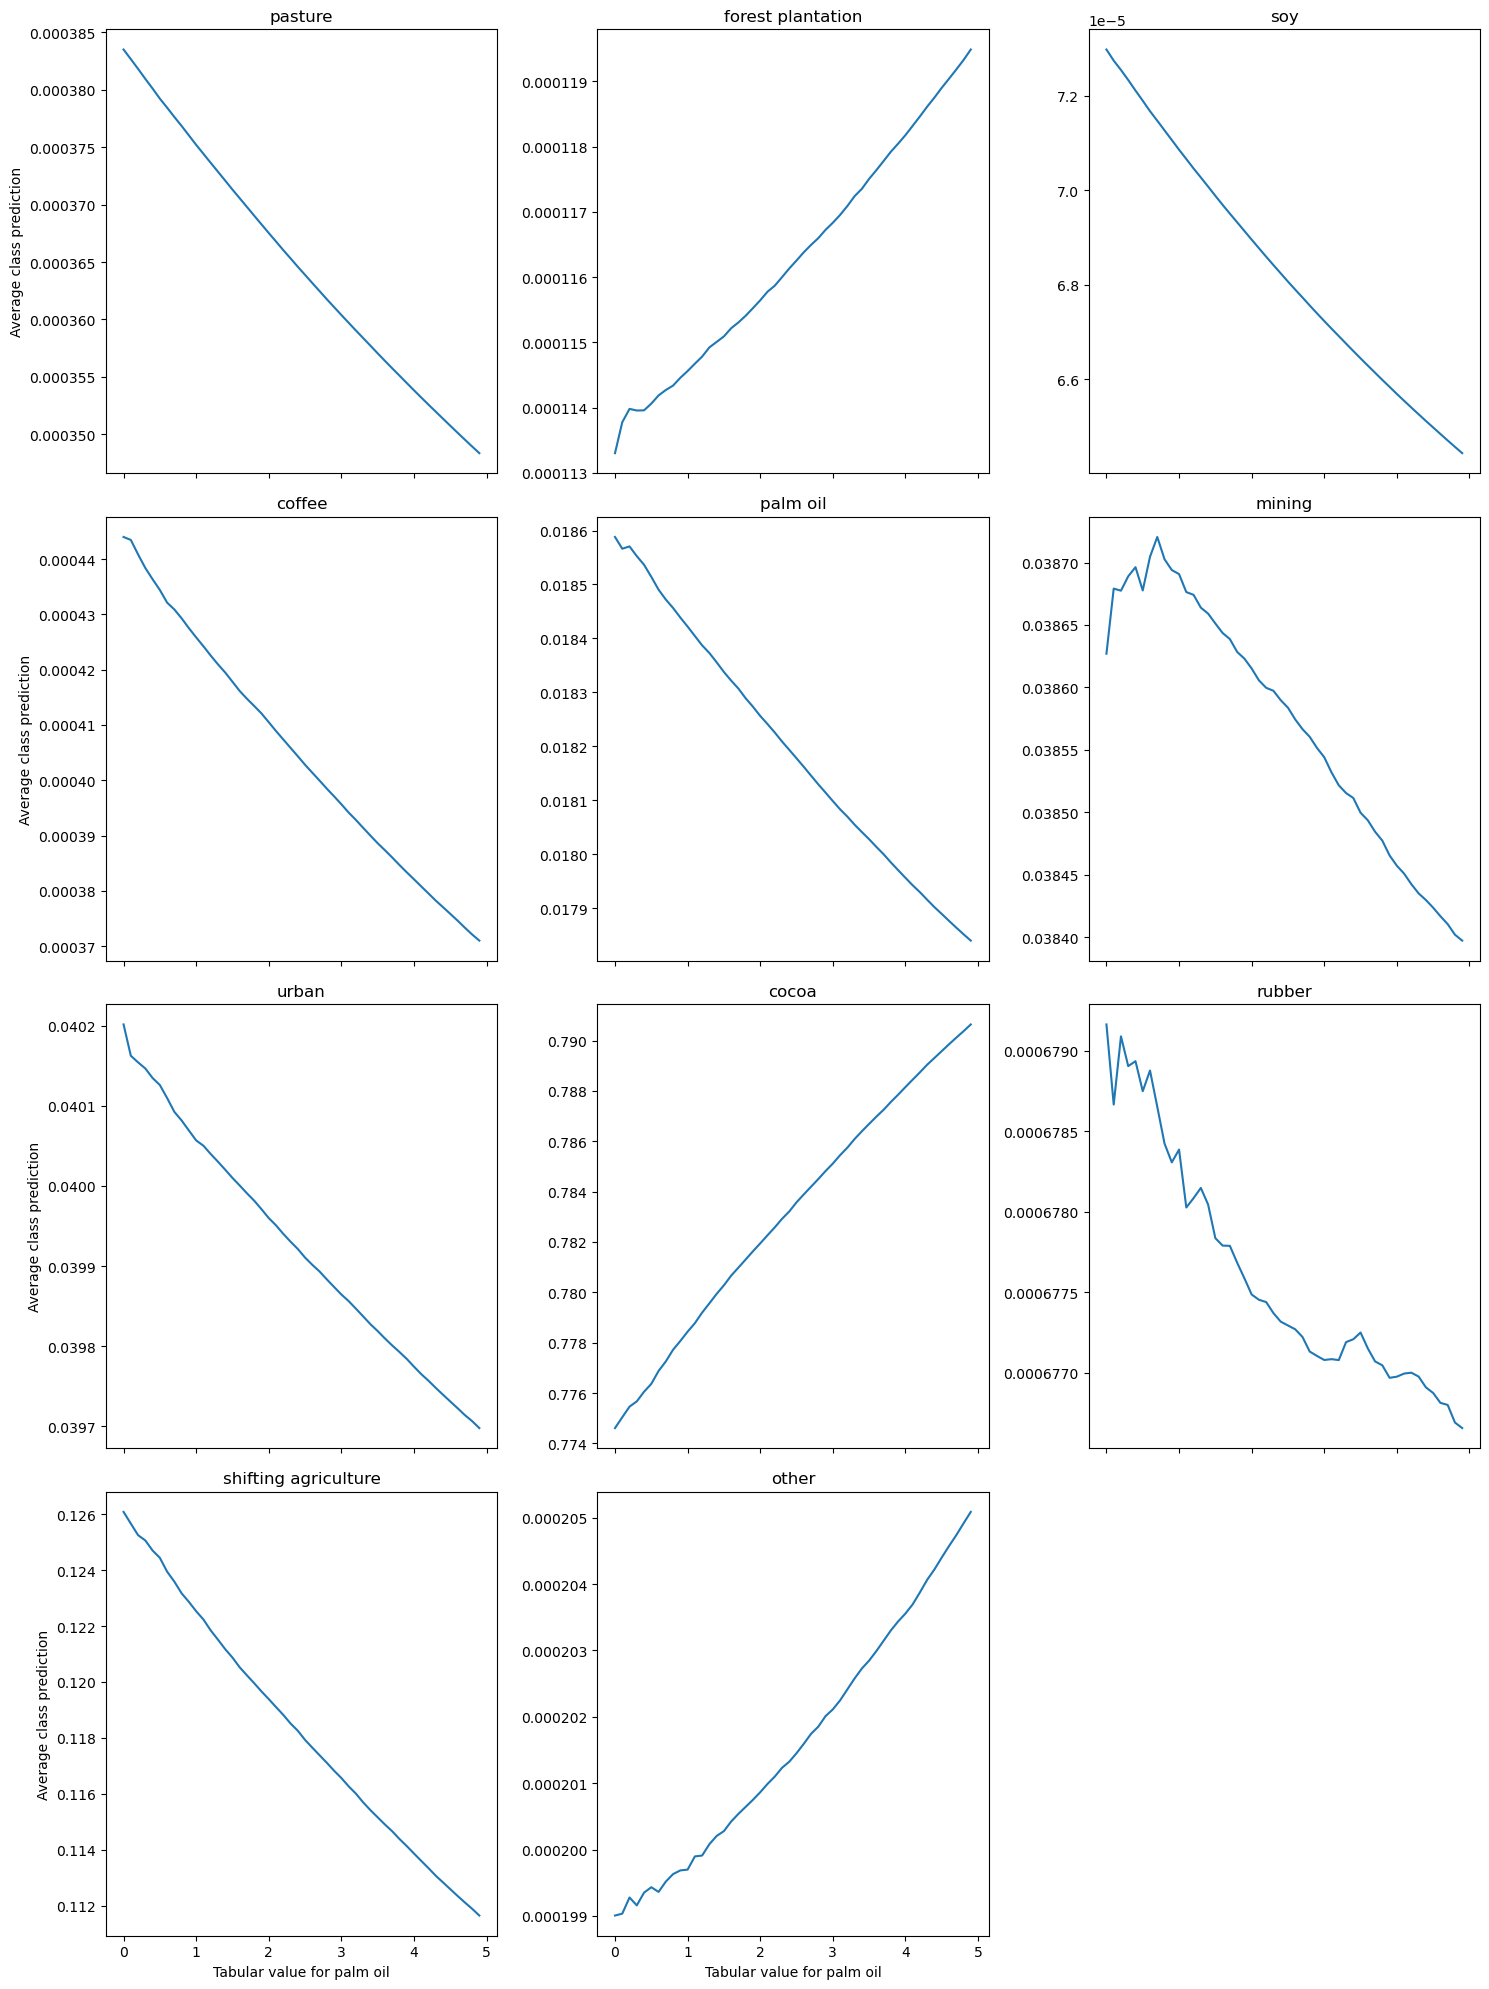

In [60]:
plot_all_classes(all_mean_probs, tab_values, class_name)




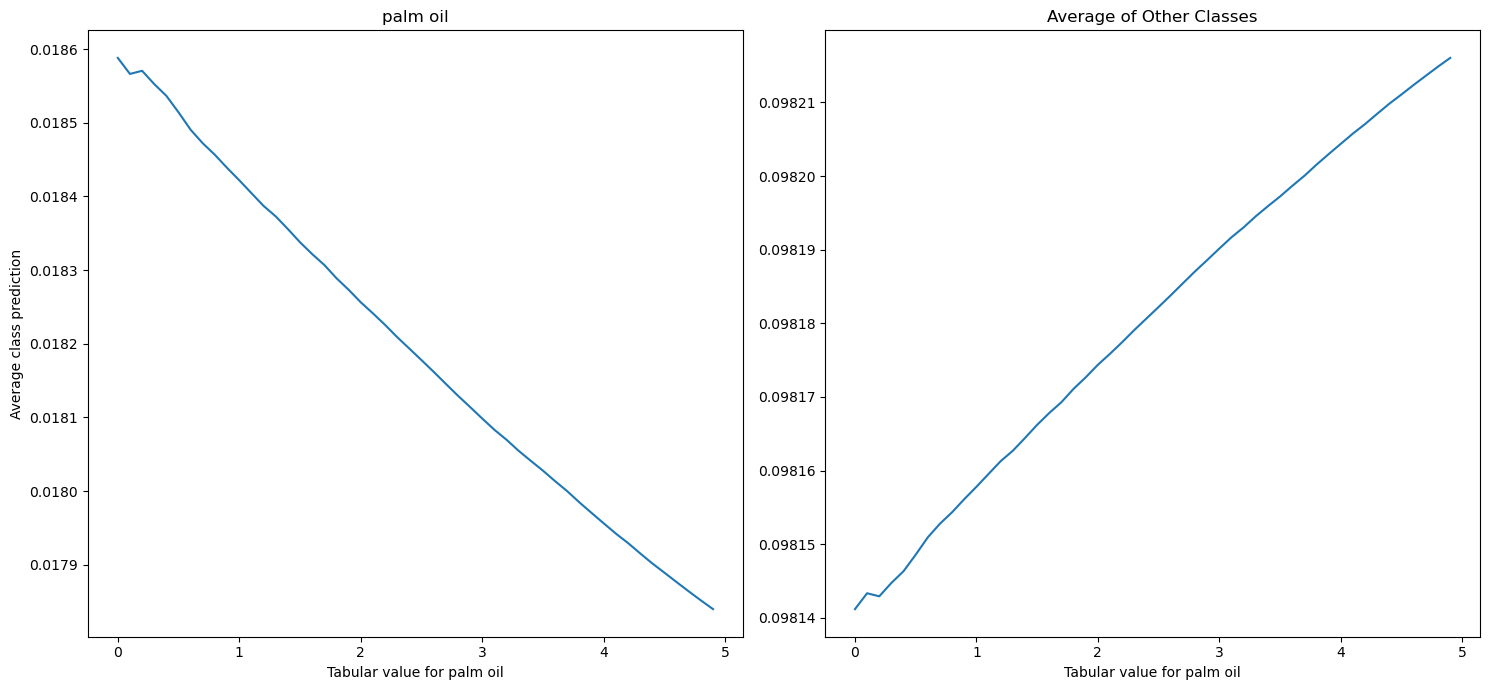

In [59]:
plot_averaged_classes(all_mean_probs, tab_values, class_name)

### Cocoa

In [63]:
class_name = "cocoa"
cls_idx = LABEL_MAPPING.get(class_name)
tab_values = [coef/10 for coef in range(50)]
_preds, all_mean_probs = get_results(cls_idx, tabular_values=tab_values, val_dl=val_dl)


0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0
3.1
3.2
3.3
3.4
3.5
3.6
3.7
3.8
3.9
4.0
4.1
4.2
4.3
4.4
4.5
4.6
4.7
4.8
4.9


In [ ]:
plot_all_classes(all_mean_probs, tab_values, class_name)




In [ ]:
plot_averaged_classes(all_mean_probs, tab_values, class_name)

## Entire test set 

In [62]:

model_dir = os.path.join('../models_trained', wandb_id)
config_path = os.path.join(model_dir, 'config.json')
with open(config_path) as source:
    config = json.loads(source.read())
    
# fetch dataloaders
dataloaders = dataloader.fetch_dataloader(
    ['val'], config)
val_dl = dataloaders['val']

In [ ]:
print(val_dl.dataset.img_labels.)

# Brazil

In [106]:
brazil = df.loc[df.country == 'Brazil']
brazil.to_csv('../data/tmp/brazil_tmp.csv',   index=False)
config['data']['annotation_file'] = '../data/tmp/brazil_tmp.csv'
# fetch dataloaders
dataloaders = dataloader.fetch_dataloader(
    ['val'], config)
val_dl = dataloaders['val']

### Cocoa